In [1]:
# ==========================================================
# SECTION 1 : IMPORT REQUIRED LIBRARIES
# ==========================================================

# Ignore warning messages for cleaner notebook output
import warnings
warnings.filterwarnings("ignore")

# File handling and model persistence
import os
import joblib

# Data manipulation libraries
import numpy as np
import pandas as pd

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# UCI dataset loader
from ucimlrepo import fetch_ucirepo

# Data splitting
from sklearn.model_selection import train_test_split

# Feature scaling
from sklearn.preprocessing import StandardScaler

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [2]:
# ==========================================================
# SECTION 2 : LOAD ADULT DATASET FROM UCI REPOSITORY
# ==========================================================

# Download Adult Income dataset directly from UCI
adult = fetch_ucirepo(id=2)

# Separate features and target variable
X = adult.data.features
y = adult.data.targets

# Combine into a single dataframe for preprocessing
df = pd.concat(
    [X, y],
    axis=1
)

# Display dataset dimensions
print("Dataset Shape :", df.shape)

# View first 5 rows
df.head()

Dataset Shape : (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
# ==========================================================
# SECTION 3 : DATA UNDERSTANDING
# ==========================================================

# Check column data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       47879 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      47876 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  48568 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 9.3 MB


In [4]:
# Statistical summary of numerical features
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [5]:
# Check distribution of target classes
df["income"].value_counts()

income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64

In [6]:
# ==========================================================
# SECTION 4 : HANDLE MISSING VALUES
# ==========================================================

# Replace unknown values (?) with NaN
df.replace(
    "?",
    np.nan,
    inplace=True
)

# Check number of missing values in each column
print(
    df.isnull().sum()
)

age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
income               0
dtype: int64


In [7]:
# Remove rows containing missing values
df.dropna(
    inplace=True
)

print(
    "Dataset Shape After Removing Missing Values:",
    df.shape
)

Dataset Shape After Removing Missing Values: (45222, 15)


In [8]:
# ==========================================================
# SECTION 5 : CLEAN TARGET VARIABLE
# ==========================================================

# Some records contain values such as:
# >50K.
# <=50K.
#
# Remove trailing periods

df["income"] = (
    df["income"]
    .str.replace(
        ".",
        "",
        regex=False
    )
)

# Verify classes
df["income"].value_counts()

income
<=50K    34014
>50K     11208
Name: count, dtype: int64

In [9]:
# ==========================================================
# SECTION 6 : ENCODE TARGET VARIABLE
# ==========================================================

# Convert labels into numeric form
#
# <=50K = 0
# >50K  = 1

df["income"] = (
    df["income"]
    .map({
        "<=50K": 0,
        ">50K": 1
    })
)

# Check for missing values after encoding
print(
    "Null Values in Target:",
    df["income"].isnull().sum()
)

Null Values in Target: 0


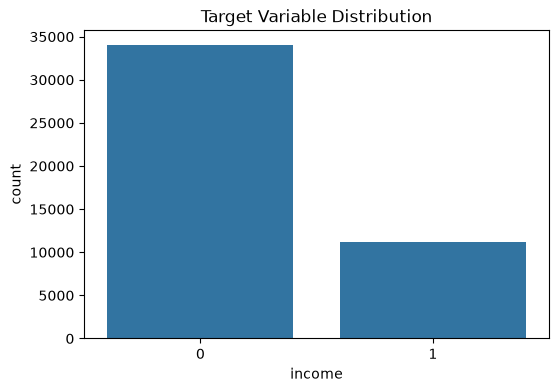

In [10]:
# ==========================================================
# SECTION 7 : CLASS DISTRIBUTION
# ==========================================================

plt.figure(
    figsize=(6,4)
)

sns.countplot(
    x="income",
    data=df
)

plt.title(
    "Target Variable Distribution"
)

plt.show()

In [11]:
# ==========================================================
# SECTION 8 : FEATURE-TARGET SEPARATION
# ==========================================================

# Remove target variable from input features
X = df.drop(
    "income",
    axis=1
)

# Store target variable separately
y = df["income"]

In [12]:
# ==========================================================
# SECTION 9 : ENCODE CATEGORICAL FEATURES
# ==========================================================

# Convert categorical variables into dummy variables

X = pd.get_dummies(
    X,
    drop_first=True
)

# Display transformed feature count
print(
    "Encoded Feature Shape:",
    X.shape
)

Encoded Feature Shape: (45222, 96)


In [13]:
# ==========================================================
# SECTION 10 : TRAIN TEST SPLIT
# ==========================================================

# Split data into
# 80% Training Data
# 20% Testing Data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Shape :", X_train.shape)
print("Testing Shape  :", X_test.shape)

Training Shape : (36177, 96)
Testing Shape  : (9045, 96)


In [14]:
# ==========================================================
# SECTION 11 : FEATURE SCALING
# ==========================================================

# Standardize features for
# Logistic Regression
# KNN
# SVM

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

In [15]:
# ==========================================================
# SECTION 12 : CREATE MODEL DIRECTORY
# ==========================================================

# Create model folder
# Required by assignment

os.makedirs(
    "model",
    exist_ok=True
)

# Save scaler for Streamlit deployment

joblib.dump(
    scaler,
    "model/scaler.pkl"
)

['model/scaler.pkl']

In [17]:
# ==========================================================
# SECTION 13 : MODEL EVALUATION FUNCTION
# ==========================================================

# Store results of all models
results = []

def evaluate_model(
        model_name,
        y_true,
        y_pred,
        y_score
):

    # Calculate metrics

    acc = accuracy_score(
        y_true,
        y_pred
    )

    auc = roc_auc_score(
        y_true,
        y_score
    )

    prec = precision_score(
        y_true,
        y_pred
    )

    rec = recall_score(
        y_true,
        y_pred
    )

    f1 = f1_score(
        y_true,
        y_pred
    )

    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )

    # Store results

    results.append([
        model_name,
        acc,
        auc,
        prec,
        rec,
        f1,
        mcc
    ])

    # Display classification report

    print("\n")
    print("=" * 60)
    print(model_name)
    print("=" * 60)

    print(
        classification_report(
            y_true,
            y_pred
        )
    )

    # Display confusion matrix

    plt.figure(figsize=(5,4))

    sns.heatmap(
        confusion_matrix(
            y_true,
            y_pred
        ),
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(
        f"Confusion Matrix - {model_name}"
    )

    plt.show()



Logistic Regression
              precision    recall  f1-score   support

           0       0.87      0.93      0.90      6803
           1       0.73      0.59      0.65      2242

    accuracy                           0.84      9045
   macro avg       0.80      0.76      0.78      9045
weighted avg       0.84      0.84      0.84      9045



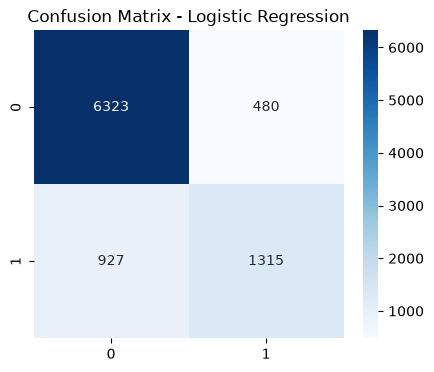

['logistic_model.pkl']

In [19]:
# ==========================================================
# SECTION 13 : LOGISTIC REGRESSION
# ==========================================================
lr = LogisticRegression(
    max_iter=1000
)

lr.fit(
    X_train_scaled,
    y_train
)

y_pred_lr = lr.predict(
    X_test_scaled
)

y_prob_lr = lr.predict_proba(
    X_test_scaled
)[:,1]

evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_lr,
    y_prob_lr
)

joblib.dump(
    lr,
    "logistic_model.pkl"
)



Decision Tree
              precision    recall  f1-score   support

           0       0.87      0.87      0.87      6803
           1       0.62      0.62      0.62      2242

    accuracy                           0.81      9045
   macro avg       0.75      0.75      0.75      9045
weighted avg       0.81      0.81      0.81      9045



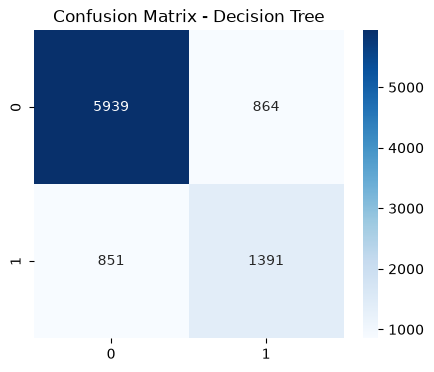

['decision_tree.pkl']

In [20]:
# ==========================================================
# SECTION 14 : DECISION TREE
# ==========================================================
dt = DecisionTreeClassifier(
    random_state=42
)

dt.fit(
    X_train,
    y_train
)

y_pred_dt = dt.predict(
    X_test
)

y_prob_dt = dt.predict_proba(
    X_test
)[:,1]

evaluate_model(
    "Decision Tree",
    y_test,
    y_pred_dt,
    y_prob_dt
)

joblib.dump(
    dt,
    "decision_tree.pkl"
)



KNN
              precision    recall  f1-score   support

           0       0.87      0.90      0.88      6803
           1       0.66      0.57      0.62      2242

    accuracy                           0.82      9045
   macro avg       0.76      0.74      0.75      9045
weighted avg       0.82      0.82      0.82      9045



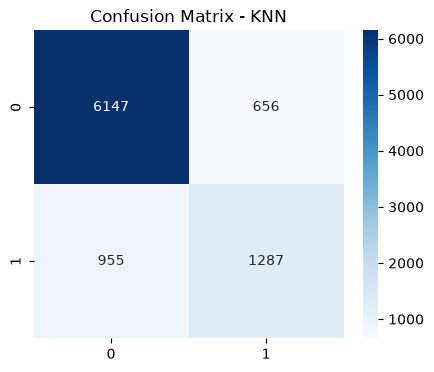

['knn_model.pkl']

In [21]:
# ==========================================================
# SECTION 15 : KNN
# ==========================================================
knn = KNeighborsClassifier(
    n_neighbors=5
)

knn.fit(
    X_train_scaled,
    y_train
)

y_pred_knn = knn.predict(
    X_test_scaled
)

y_prob_knn = knn.predict_proba(
    X_test_scaled
)[:,1]

evaluate_model(
    "KNN",
    y_test,
    y_pred_knn,
    y_prob_knn
)

joblib.dump(
    knn,
    "knn_model.pkl"
)



Naive Bayes
              precision    recall  f1-score   support

           0       0.96      0.44      0.60      6803
           1       0.36      0.95      0.52      2242

    accuracy                           0.57      9045
   macro avg       0.66      0.69      0.56      9045
weighted avg       0.81      0.57      0.58      9045



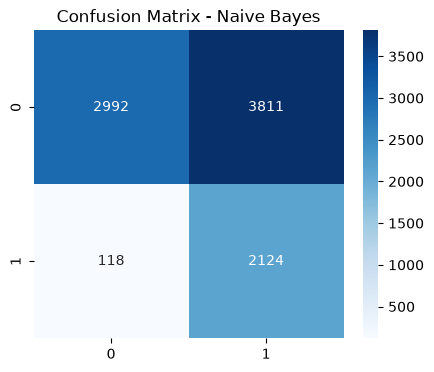

['naive_bayes.pkl']

In [22]:
# ==========================================================
# SECTION 16 : NAIVE BAYES
# ==========================================================
nb = GaussianNB()

nb.fit(
    X_train_scaled,
    y_train
)

y_pred_nb = nb.predict(
    X_test_scaled
)

y_prob_nb = nb.predict_proba(
    X_test_scaled
)[:,1]

evaluate_model(
    "Naive Bayes",
    y_test,
    y_pred_nb,
    y_prob_nb
)

joblib.dump(
    nb,
    "naive_bayes.pkl"
)



Support Vector Machine
              precision    recall  f1-score   support

           0       0.87      0.93      0.90      6803
           1       0.74      0.58      0.65      2242

    accuracy                           0.85      9045
   macro avg       0.81      0.76      0.78      9045
weighted avg       0.84      0.85      0.84      9045



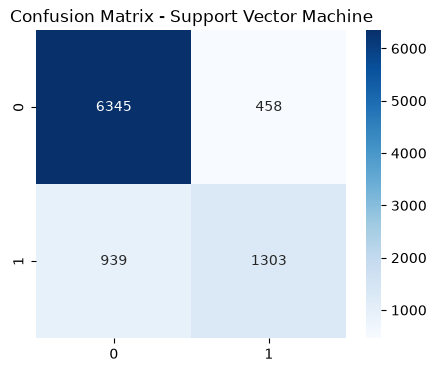

['svm_model.pkl']

In [23]:
# ==========================================================
# SECTION 17 : SUPPORT VECTOR MACHINE
# ==========================================================
from sklearn.svm import LinearSVC

svm = LinearSVC(
    random_state=42
)

svm.fit(
    X_train_scaled,
    y_train
)

y_pred_svm = svm.predict(
    X_test_scaled
)

y_score_svm = svm.decision_function(
    X_test_scaled
)

evaluate_model(
    "Support Vector Machine",
    y_test,
    y_pred_svm,
    y_score_svm
)
joblib.dump(
    svm,
    "svm_model.pkl"
)

In [24]:
# ==========================================================
# SECTION 18 : MODEL COMPARISON TABLE
# ==========================================================
results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "AUC",
        "Precision",
        "Recall",
        "F1 Score",
        "MCC"
    ]
)

In [25]:
# ==========================================================
# SECTION 19 : BEST MODEL IDENTIFICATION
# ==========================================================
winner = results_df.sort_values(
    by='Accuracy',
    ascending=False
)

winner.head(1)

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
5,Support Vector Machine,0.84555,0.902236,0.73992,0.581178,0.651012,0.560329


In [26]:
print(
    "Best Model :",
    winner.iloc[0]['Model']
)

Best Model : Support Vector Machine


In [27]:
results_df.to_csv(
    "model_comparison.csv",
    index=False
)

In [28]:
test_data = X_test.copy()

test_data['income'] = y_test

test_data.to_csv(
    "test_data.csv",
    index=False
)

print(
    "test_data.csv saved successfully."
)

test_data.csv saved successfully.
